In [1]:
import torch
import torch.nn as nn 
import matplotlib.pyplot as plt
import numpy as np
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [2]:
bc_coeff = torch.load('./results/diffusion/bc_coeff_20_3.pt')
# Add the homogeneous BCs for t=0
bc_coeffs = torch.cat([torch.tensor([0.0]), bc_coeff, torch.tensor([0.0])])
bc_coeffs.shape

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_13352\3570212726.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  bc_coeff = torch.load('./results/diffusion/bc_coeff_20_3

torch.Size([20])

In [3]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-1, n_basis-2)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        # self.coeffs_row_0=torch.tensor([0.0, 0.3162,  0.8723,  1.1328,  0.4845, -0.4881, -1.1225, -0.8896, -0.3011,0.0])
        self.coeffs_row_0=bc_coeffs
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x
        
        
        # Bsplines for the two dimensions
        ################Changes#################
        # self.D = torch.rand(1)
        # self.D.requires_grad_()
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])
        
        
        y = torch.zeros(x.shape[0])
        # Adding the internal domain bsplines
        for i in range(1,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-1, j-1] * self.B_t[i]*self.B_x[j]
        
        # Adding the IC 
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y
    
    def D(self):
        return self.softplus(self.raw_D)
    
   


Class for noisy data where we can not impose exact conditions

In [7]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree, device):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.zeros(n_basis, n_basis, device=device, requires_grad=True)

        # 2D input
        # self.x = x
        
        
        # Bsplines for the two dimensions
        ################Changes#################
        # self.D = torch.rand(1)
        # self.D.requires_grad_()
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32, device=device))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x, device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])
        
        
        y = torch.zeros(x.shape[0], device=device)

        for i in range(self.n_basis):
            for j in range(self.n_basis):
                y += self.coeffs_trainable[i, j] * self.B_t[i]*self.B_x[j]



        return y
    
    def D(self):
        return self.softplus(self.raw_D)
    
    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))
    
   


In [8]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
torch.manual_seed(42)

# model = bsplines2D(10,3)
# If We dont get good fit, train the BC for 20,3 and use here 20,3
# model = bsplines2D(20,2)
model = bsplines2D(20,3, device)
model.coeffs_trainable.device


device(type='cuda', index=0)

In [10]:
model.to(device)

In [11]:
model.D()

tensor([0.7444], device='cuda:0', grad_fn=<SoftplusBackward0>)

In [12]:
colloc_points = 5000

# Reproducable input points
torch.manual_seed(42)

#X[:,0] is x and X[:,1] is time
#########Change###########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)
#########Change###########
u_exact = torch.sin(2*torch.pi * X[:,0]) * torch.exp(-torch.pi**2 *0.03* X[:,1]*4)
u_exact = u_exact.to(device)
noise = torch.normal(mean=0.0, std=0.05, size=u_exact.shape)
noise = noise.to(device)
u_noisy = u_exact + noise
#########Change###########
X = X.to(device)
X.requires_grad_(True)

tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], device='cuda:0', requires_grad=True)

In [14]:
epochs = 5000
learning_rate=1e-3

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable, model.raw_D], lr=learning_rate)
###########Changes#################

loss_vec = []
for epoch in range(epochs):
    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(X, device)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]

    ###########Changes#################
    D = model.D()
    # Residual loss
    res = u_t -D*u_xx 
    
    loss_pde = torch.mean(res**2)
    
    loss_data = torch.mean((u - u_noisy)**2) 

    loss = loss_pde + loss_data
    ###########Changes#################

    loss.backward()
    ###########Changes#################
    optimizer.step()
    ###########Changes#################

    loss_vec.append(loss_data.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        D_est = D.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {D_est:.5f}")
        # print(f"Epoch {epoch:5d} | Loss: {loss_data.item()} ")

Epoch     4 | Loss: 4.0264e-01 | D: 0.74269


KeyboardInterrupt: 

In [6]:
print(model.D().item())

0.7443966865539551


In [9]:
#Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/diffusion_inverse/bsplines_loss_noise.npy', loss_vec_npy )

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable, 'D_trainable': model.raw_D }
torch.save(params, './results/diffusion_inverse/model_bsplines_noise.pth')

In [5]:
# Load model trainable parameters
model_s = bsplines2D(20,3)
loaded_params = torch.load('./results/diffusion_inverse/model_bsplines.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']
model_s.raw_D = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_31040\3282493418.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/diffusion_inverse/

In [6]:
# Load loss
loss_bsplines_s = np.load('./results/diffusion_inverse/bsplines_loss.npy')

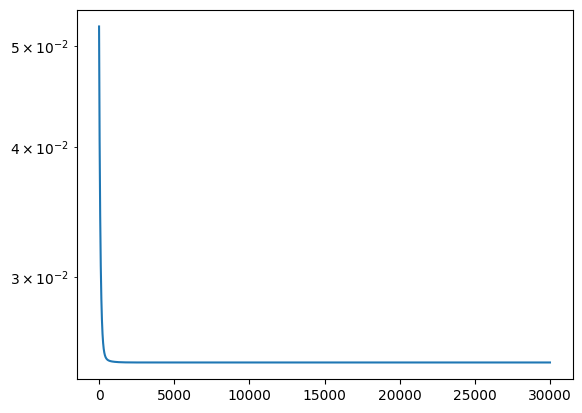

In [16]:
plt.plot(loss_vec)
plt.yscale('log')

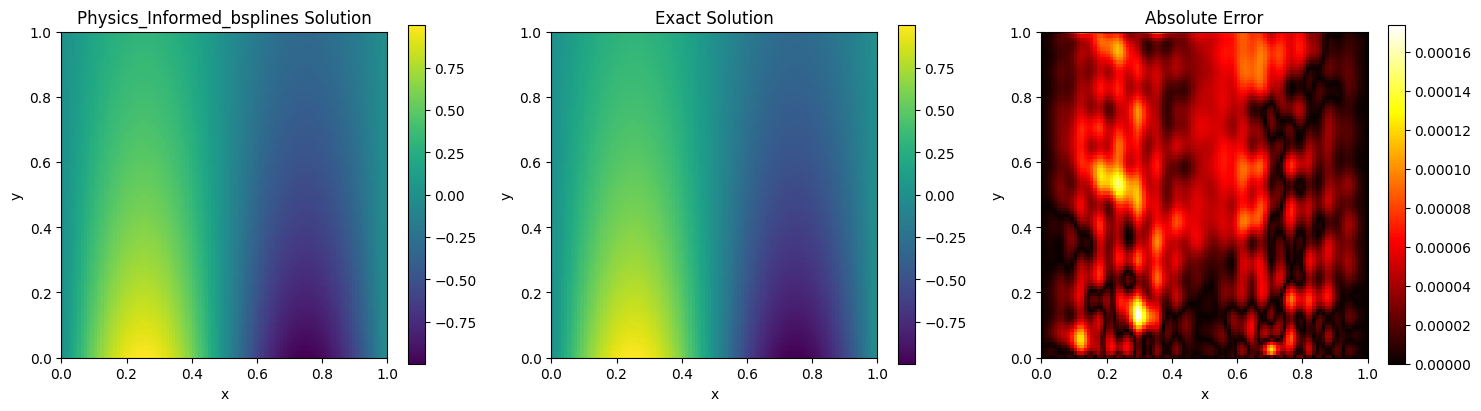

In [9]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Tg*4)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

PINN solution

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Set device and seed
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

# True parameter
D_true = 0.03

# Synthetic solution: u(x,t) = sin(2πx) * exp(-4π² D t)
def analytical_solution(x, t, D):
    return torch.sin(2 * np.pi * x) * torch.exp(-4 * np.pi**2 * D * t)

# Neural network model
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 99), nn.Tanh(),
            nn.Linear(99, 1)
        )
        self.raw_D = nn.Parameter(torch.tensor([0.1], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

    def D(self):
        return self.softplus(self.raw_D)  # ensures positivity

# PDE residual
def pde_residual(model, x, t):
    x.requires_grad_(True)
    t.requires_grad_(True)
    u = model(x, t)
    D = model.D()

    u_t = torch.autograd.grad(u, t, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, torch.ones_like(u), retain_graph=True, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u), create_graph=True)[0]

    f = u_t - D * u_xx
    return f

# Sample data
N_data = 100
N_colloc = 5000


x_colloc = torch.rand(N_colloc, 1, device=device)
t_colloc = torch.rand(N_colloc, 1, device=device)
# x_data = torch.rand(N_data, 1, device=device)
# t_data = torch.rand(N_data, 1, device=device)
u_data = analytical_solution(x_colloc, t_colloc, D_true)

# Add noise
noise = torch.normal(mean=0.0, std=0.05, size=u_data.shape, device=device)
u_noisy = u_data + noise


# Initialize model
model = PINN().to(device)


In [2]:
noise

tensor([[-0.0259],
        [ 0.0613],
        [ 0.0313],
        ...,
        [ 0.0668],
        [ 0.0354],
        [ 0.0194]], device='cuda:0')

In [3]:
# Training loop
# First 10000 1e-3 and then 1e-4

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.8, patience=10, min_lr=1e-5)

loss_history = []
for epoch in range(10000):
    optimizer.zero_grad()
    
    ##### Changes ####### 
    u_pred = model(x_colloc, t_colloc)
    ##### Changes ####### 

    loss_data = torch.mean((u_pred - u_noisy)**2)
    
    f = pde_residual(model, x_colloc, t_colloc)
    loss_pde = torch.mean(f**2)
    
    loss = loss_data + loss_pde
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if epoch % 500 == 0:
        D_est = model.D().item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():.4e} | D: {D_est:.5f}")
        

# Final estimated D
print(f"\nEstimated D: {model.D().item():.5f} (True D: {D_true})")

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch     0 | Loss: 2.2476e-01 | D: 0.74434
Epoch   500 | Loss: 8.3738e-02 | D: 0.73176
Epoch  1000 | Loss: 7.8300e-02 | D: 0.72424


KeyboardInterrupt: 

In [23]:
#Save loss
loss_vec_npy = np.array(loss_history)
np.save('./results/diffusion_inverse/pinn_loss.npy', loss_vec_npy )

#Save model trainable parameters
torch.save(model.state_dict(), './results/diffusion_inverse/model_pinn.pth')

In [8]:
#Save loss
loss_vec_npy = np.array(loss_history)
np.save('./results/diffusion_inverse/pinn_loss.npy', loss_vec_npy )

#Save model trainable parameters
torch.save(model.state_dict(), './results/diffusion_inverse/model_pinn.pth')

NameError: name 'loss_history' is not defined

In [9]:
model_ps = PINN()


In [10]:
model_ps.load_state_dict(torch.load('./results/diffusion_inverse/model_pinn.pth'))


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_31040\3846484119.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_ps.load_state_dict(torch.load('./results/diffusion

<All keys matched successfully>

In [11]:
loss_pinn = np.load('./results/diffusion_inverse/pinn_loss.npy')


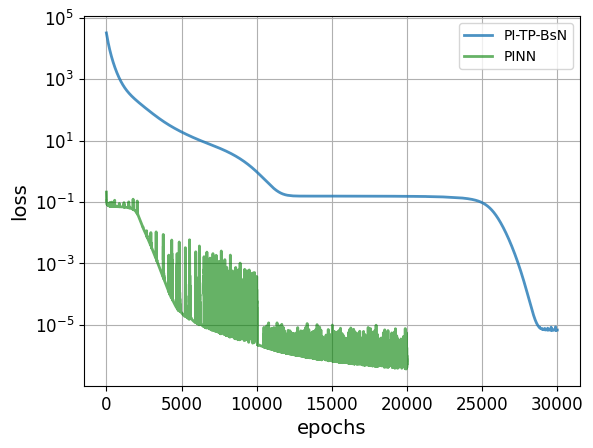

In [25]:

x_a = np.arange(len(loss_bsplines_s))
x_b = np.arange(len(loss_pinn))
plt.plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
plt.plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
plt.legend()
plt.yscale('log')
# plt.title("Losses",fontsize=14)
plt.xlabel("epochs",fontsize=14)
plt.ylabel("loss",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)

plt.savefig("loss_inv_diff.pdf", dpi=300)
plt.show()

In [14]:
re=np.sqrt((model_s.D().item() - 0.03)**2)/np.sqrt(0.03**2)
re

9.397665659549581e-06

In [15]:
re_p=np.sqrt((model_ps.D().item() - 0.03)**2)/np.sqrt(0.03**2)
re_p

0.00013110786676410563

In [16]:
(re_p-re)/re_p

0.9283211153419327

In [69]:
print(model_s.D().item())


0.02992246299982071


In [36]:
XY_torch[:,0].shape

torch.Size([10000])

In [18]:
# 🔍 Evaluate on a test grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
with torch.no_grad():
    u_predp = model_ps.forward(XY_torch[:,0].reshape(XY_torch[:,0].shape[0],1), XY_torch[:,1].reshape(XY_torch[:,0].shape[0],1)).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Tg*4)

In [23]:
u = np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
u

9.997814215739471e-05

In [20]:
up = np.sqrt(np.sum((u_predp - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
up

0.0009815484019931036

In [24]:
(up-u)/up

0.8981424227736686

In [76]:
loss_pinn[-1]

0.0024573819246143103

In [74]:
(5.68-1.38)/5.68

0.7570422535211268